id: notebooks/09_spectral_lines.ipynb

spectral lines: channels and velocities, Doppler correction to the LSR, OH masers and HI absorption on the 11.5 km baseline, channel maps

<!-- notebooks/09_spectral_lines.ipynb -- spectral lines (Interferosim 0.9.0) -->
# 09 – Spectral lines: HI and OH masers

---
  DI Erich Schubert, 07925151
  


Up to now every source had one flux density. The two targets that justify the project are spectral lines: the **OH masers** at 1665/1667 MHz, compact enough for an 11.5 km baseline, and the **21 cm line of neutral hydrogen**, seen in absorption against bright continuum sources. The correlator delivers a cross spectrum per baseline anyway (notebook 05); this notebook gives the sky models spectra, follows the lines through the Doppler shifts of the Earth's motion, and images them channel by channel.

Package: `interferosim.sky` – `GaussianLineSpectrum`, `AbsorptionSpectrum`, `PowerLawSpectrum`, `SkyModel.spectra`, `flux_at`, `at_frequency`, `spectrum_jy`; `interferosim.observation` – `v_lsr_correction_kms`, `topocentric_frequency_hz`, `regrid_to_lsr`, `SpectralVisibilitySimulator`; `interferosim.imaging` – `Imager.channel_images`. All new in 0.9.0.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT, HI_21CM, OH_1665, OH_1667
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel, radio_velocity_kms, frequency_from_velocity
from interferosim.observation import (Observation, SpectralVisibilitySimulator, v_lsr_correction_kms,
                                      topocentric_frequency_hz, regrid_to_lsr, mjd_from_iso)
from interferosim.imaging import Gridder, Imager, NaturalWeighting
from interferosim.plotting import plot_image, sky_marks

CFG = Path("..") / "configs"
DATE = "2026-11-01"
C_KMS = C_LIGHT / 1000
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
target = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                      Station.from_enu("X", site, 11_500, 0, 0, dish)], receiver=b210,
               name="project baseline 11.5 km east-west (model)")
three = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                     Station.from_enu("E", site, 11_500, 0, 0, dish),
                     Station.from_enu("N", site, 0, 6_000, 0, dish)], receiver=b210,
              name="hypothetical three-station array")
masers = SkyModel.from_json(CFG / "skies" / "w3oh_masers_lines.json")
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a_hi.json")
M1 = (masers["Maser M1"].dx_deg, masers["Maser M1"].dy_deg)
REF = target.reference
for c in masers:
    sp = masers.spectra[c.name]
    print(f"{c.name}: peak {c.flux_jy:5.1f} Jy, v_LSR {sp.v_kms:+6.1f} km/s, FWHM {sp.fwhm_kms} km/s")

Maser M1: peak  70.0 Jy, v_LSR  -44.0 km/s, FWHM 0.4 km/s
Maser M2: peak  45.0 Jy, v_LSR  -45.8 km/s, FWHM 0.4 km/s
Maser M3: peak  20.0 Jy, v_LSR  -42.3 km/s, FWHM 0.4 km/s


## 1. Channels and velocities

A line is described by its velocity along the line of sight, in the **radio convention** relative to the rest frequency $f_0$:

$$v = c\,\frac{f_0 - f}{f_0}, \qquad \Delta v = c\,\frac{\Delta f}{f_0}.$$

The FX correlator splits the recorded band $B$ into $N$ channels of width $\Delta f = B/N$ (notebook 05). OH masers have line widths of a few tenths of a km/s, HI absorption features a few km/s – the channel must be narrower than the line. The noise per channel grows with $1/\sqrt{\Delta f}$: a narrow channel costs sensitivity.

In [2]:
sefd = b210.sefd_jy(dish, OH_1665)
print(f"{'band':>9s} {'N':>6s} {'channel':>10s} {'HI [km/s]':>10s} {'OH [km/s]':>10s} {'sigma 1 min [Jy]':>17s}")
for bw, n in [(2e6, 64), (2e6, 2048), (1e6, 128), (250e3, 256), (125e3, 128), (62.5e3, 256)]:
    df = bw / n
    print(f"{bw / 1e3:7.1f} kHz {n:6d} {df:8.0f} Hz {C_KMS * df / HI_21CM:10.3f} {C_KMS * df / OH_1665:10.3f} "
          f"{sefd / np.sqrt(2 * df * 60):17.0f}")
print(f"\n(one baseline of two 3 m dishes, SEFD {sefd / 1e3:.0f} kJy; the notebooks so far used 2 MHz / 64 channels)")

     band      N    channel  HI [km/s]  OH [km/s]  sigma 1 min [Jy]
 2000.0 kHz     64    31250 Hz      6.596      5.625                40
 2000.0 kHz   2048      977 Hz      0.206      0.176               228
 1000.0 kHz    128     7812 Hz      1.649      1.406                81
  250.0 kHz    256      977 Hz      0.206      0.176               228
  125.0 kHz    128      977 Hz      0.206      0.176               228
   62.5 kHz    256      244 Hz      0.052      0.044               456

(one baseline of two 3 m dishes, SEFD 78 kJy; the notebooks so far used 2 MHz / 64 channels)


## 2. Doppler correction to the LSR

Line velocities are catalogued relative to the **local standard of rest** (LSR). The observer moves relative to the LSR with the Earth's rotation (0.31 km/s at Wilhelmsburg, one sidereal day), the orbit (≈ 30 km/s, one year) and the solar motion (20 km/s towards RA 18 h, Dec +30°). With $\hat s$ towards the source:

$$v_\mathrm{LSR} = v_\mathrm{topo} + \vec v_\mathrm{obs}\cdot\hat s .$$

`v_lsr_correction_kms` returns $\vec v_\mathrm{obs}\cdot\hat s$ (checked against astropy within 0.02 km/s). The correction shifts a line by tens of km/s over the year – many channels – and by up to ±0.3 km/s within a day: one or two channels of a maser spectrum.

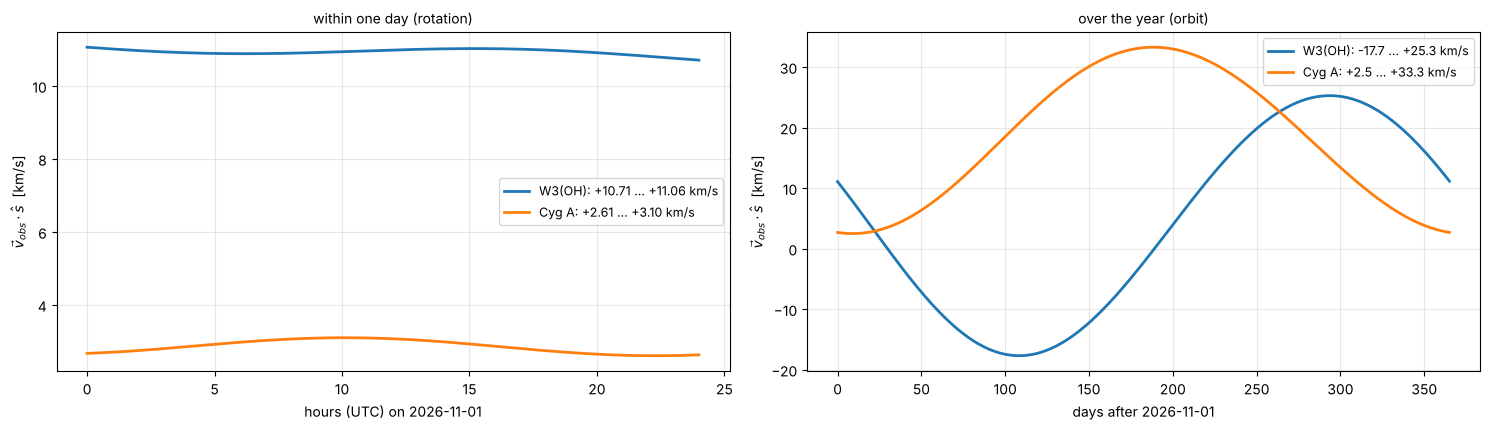

maser M1 (v_LSR = -44.0 km/s) on 2026-11-01 12 UTC: observed at 1665.70744 MHz, +61.0 kHz from its LSR frequency


In [3]:
t0 = mjd_from_iso(DATE)
day = t0 + np.linspace(0, 1, 289)
year = t0 + np.linspace(0, 365, 366)
srcs = {"W3(OH)": (masers.center.ra_deg, masers.center.dec_deg), "Cyg A": (cyga.center.ra_deg, cyga.center.dec_deg)}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for name, (ra, dec) in srcs.items():
    vc_d = v_lsr_correction_kms(ra, dec, day, REF.lat_deg, REF.lon_deg, REF.height_m)
    vc_y = v_lsr_correction_kms(ra, dec, year, REF.lat_deg, REF.lon_deg, REF.height_m)
    axes[0].plot((day - t0) * 24, vc_d, lw=2, label=f"{name}: {vc_d.min():+.2f} ... {vc_d.max():+.2f} km/s")
    axes[1].plot(year - t0, vc_y, lw=2, label=f"{name}: {vc_y.min():+.1f} ... {vc_y.max():+.1f} km/s")
axes[0].set(xlabel=f"hours (UTC) on {DATE}", ylabel=r"$\vec v_{obs}\cdot\hat s$  [km/s]", title="within one day (rotation)")
axes[1].set(xlabel=f"days after {DATE}", ylabel=r"$\vec v_{obs}\cdot\hat s$  [km/s]", title="over the year (orbit)")
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=9); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
ra, dec = srcs["W3(OH)"]
f_t = topocentric_frequency_hz(OH_1665, -44.0, ra, dec, t0 + 0.5, REF.lat_deg, REF.lon_deg, REF.height_m)
print(f"maser M1 (v_LSR = -44.0 km/s) on {DATE} 12 UTC: observed at {f_t / 1e6:.5f} MHz, "
      f"{(f_t - frequency_from_velocity(-44.0, OH_1665)) / 1e3:+.1f} kHz from its LSR frequency")

## 3. Sky models with spectra

* `w3oh_masers_lines` – the maser group of notebooks 06/07, each maser with a Gaussian 1665 MHz line (FWHM 0.4 km/s) at its own velocity between −45.8 and −42.3 km/s (illustrative values near the systemic velocity of W3(OH)); `flux_jy` is the peak flux density.
* `cyg_a_hi` – Cygnus A with a synchrotron spectrum ($\alpha = -0.7$, core flat) and Galactic HI absorption on all components: τ = 0.6 at +3 km/s (Local arm) and τ = 0.3 at −80 km/s (Perseus arm) – illustrative values.

The JSON entry of a component simply gets a `"spectrum"` key; models without it stay flat.

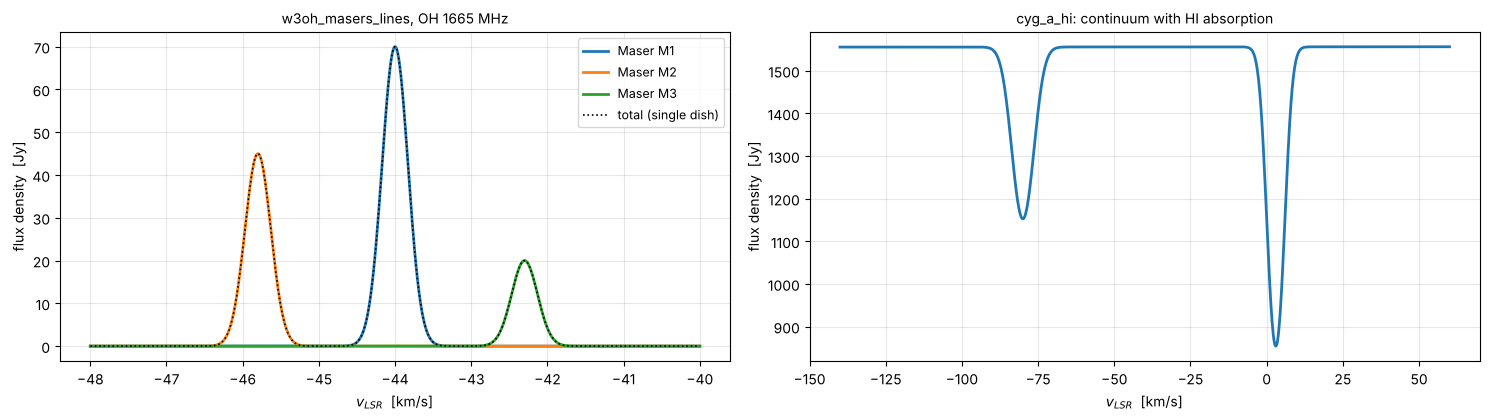

all tools of notebooks 04-07 still work: SkyModel.at_frequency(f) gives the continuum snapshot at f, e.g. M1 at -44 km/s: 70.0 Jy


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
v = np.linspace(-48, -40, 800)
for c in masers:
    axes[0].plot(v, masers.flux_at(c, frequency_from_velocity(v, OH_1665)), lw=2, label=c.name)
axes[0].plot(v, masers.spectrum_jy(frequency_from_velocity(v, OH_1665)), "k:", lw=1.2, label="total (single dish)")
axes[0].set(xlabel=r"$v_{LSR}$  [km/s]", ylabel="flux density  [Jy]", title="w3oh_masers_lines, OH 1665 MHz")
vh = np.linspace(-140, 60, 1000)
axes[1].plot(vh, cyga.spectrum_jy(frequency_from_velocity(vh, HI_21CM)), lw=2)
axes[1].set(xlabel=r"$v_{LSR}$  [km/s]", ylabel="flux density  [Jy]", title="cyg_a_hi: continuum with HI absorption")
for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
axes[0].legend(fontsize=9); fig.tight_layout(); plt.show()
print("all tools of notebooks 04-07 still work: SkyModel.at_frequency(f) gives the continuum snapshot at f,",
      f"e.g. M1 at -44 km/s: {masers.at_frequency(frequency_from_velocity(-44.0, OH_1665))['Maser M1'].flux_jy:.1f} Jy")

## 4. OH masers on the 11.5 km baseline

`SpectralVisibilitySimulator`: band 125 kHz, 128 channels (0.18 km/s), LO fixed at the frequency of −44 km/s at transit, ±8 h, one-minute integrations, two 3 m dishes. Every channel is evaluated at its own spatial frequency and with the spectra of the components; with `doppler=True` the channels are converted to the LSR frame for every integration, so the lines drift through the topocentric channels over the night. `regrid_to_lsr` interpolates every row onto a common LSR velocity axis – Doppler tracking in software.

**Spectrum towards a position.** Shifting the phase centre to one maser and averaging the visibilities over the track adds that maser coherently; the others rotate in phase and average out. One baseline thus separates the three spectra without an image.

957 integrations x 128 channels of 977 Hz, noise per visibility and channel 228 Jy, mean LSR correction +10.78 km/s


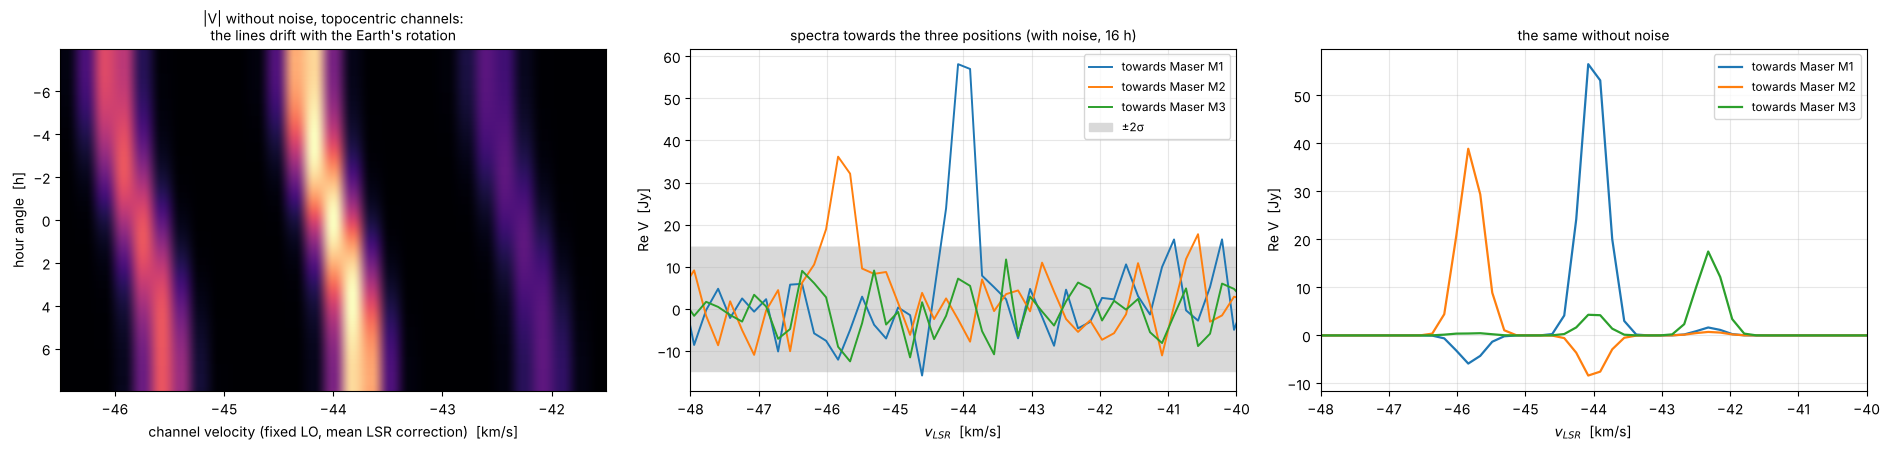

Maser M1: Re V at -44.08 km/s =  58.1 ± 7.4 Jy (true peak 70 Jy, apparent with primary beam and channel sampling 56.5 Jy)
Maser M2: Re V at -45.84 km/s =  36.1 ± 7.4 Jy (true peak 45 Jy, apparent with primary beam and channel sampling 38.9 Jy)
Maser M3: Re V at -42.32 km/s =   6.3 ± 7.4 Jy (true peak 20 Jy, apparent with primary beam and channel sampling 17.5 Jy)


In [5]:
obs = Observation.from_sky(masers, target, ha_range_h=(-8, 8), t_int_s=60, freq_hz=OH_1665, date=DATE)
ssim = SpectralVisibilitySimulator(n_chan=128, bandwidth_hz=125e3, rest_hz=OH_1665, v_center_kms=-44.0)
vd = ssim.run(masers, obs)
vd0 = SpectralVisibilitySimulator(n_chan=128, bandwidth_hz=125e3, rest_hz=OH_1665, v_center_kms=-44.0,
                                  add_noise=False).run(masers, obs)
VAX = np.arange(-49.0, -39.0 + 1e-9, C_KMS * vd.header["CHANWID"] / OH_1665)
rg = regrid_to_lsr(vd, target, OH_1665, VAX)
rg0 = regrid_to_lsr(vd0, target, OH_1665, VAX)
print(f"{vd.n_rows} integrations x {vd.n_chan} channels of {vd.header['CHANWID']:.0f} Hz, "
      f"noise per visibility and channel {vd.sigma[0, 0]:.0f} Jy, mean LSR correction {vd.header['VLSRCORR']:+.2f} km/s")

def spectrum_towards(d, l_deg, m_deg):
    """Vector average over all rows after shifting the phase centre to (l, m) offset from the field centre."""
    s = d.freq_hz / d.freq_hz[0]
    ph = np.exp(2j * np.pi * (np.outer(d.u, s) * np.radians(l_deg) + np.outer(d.v, s) * np.radians(m_deg)))
    w = d.weight
    return (d.vis * ph * w).sum(0) / np.maximum(w.sum(0), 1e-300), 1 / np.sqrt(np.maximum(w.sum(0), 1e-300))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
t_h = (vd0.ha_deg - 0) / 15
ext = (VAX[0], VAX[-1], t_h[-1], t_h[0])
k1 = masers.spectra["Maser M1"]
sel = slice(0, vd0.n_rows)
v_topo = radio_velocity_kms(vd0.freq_hz, OH_1665) + vd0.header["VLSRCORR"]
axes[0].imshow(np.abs(vd0.vis * np.exp(2j * np.pi * (np.outer(vd0.u, vd0.freq_hz / vd0.freq_hz[0]) * np.radians(M1[0])
                                                    + np.outer(vd0.v, vd0.freq_hz / vd0.freq_hz[0]) * np.radians(M1[1])))),
               aspect="auto", origin="upper", cmap="magma",
               extent=(v_topo[0], v_topo[-1], t_h[-1], t_h[0]))
axes[0].set(xlim=(-46.5, -41.5), xlabel="channel velocity (fixed LO, mean LSR correction)  [km/s]", ylabel="hour angle  [h]",
            title="|V| without noise, topocentric channels:\nthe lines drift with the Earth's rotation")
for (name, l, m), col in zip([(c.name, c.dx_deg, c.dy_deg) for c in masers], ("C0", "C1", "C2")):
    s, e = spectrum_towards(rg, l, m)
    axes[1].plot(VAX, s.real, color=col, lw=1.4, label=f"towards {name}")
    s0, _ = spectrum_towards(rg0, l, m)
    axes[2].plot(VAX, s0.real, color=col, lw=1.6, label=f"towards {name}")
axes[1].fill_between(VAX, -2 * e, 2 * e, color="0.85", label="±2σ")
axes[1].set(title="spectra towards the three positions (with noise, 16 h)")
axes[2].set(title="the same without noise")
for ax in axes[1:]:
    ax.set(xlabel=r"$v_{LSR}$  [km/s]", ylabel="Re V  [Jy]", xlim=(-48, -40)); ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
for ax in axes: ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
for c in masers:
    s, e = spectrum_towards(rg, c.dx_deg, c.dy_deg)
    k = np.argmin(np.abs(VAX - masers.spectra[c.name].v_kms))
    print(f"{c.name}: Re V at {VAX[k]:+.2f} km/s = {s[k].real:5.1f} ± {e[k]:.1f} Jy (true peak {c.flux_jy:.0f} Jy, "
          f"apparent with primary beam and channel sampling {abs(spectrum_towards(rg0, c.dx_deg, c.dy_deg)[0][k]):.1f} Jy)")

The noise of a single channel is large (two 3 m dishes, 1 kHz channels: ≈ 230 Jy per minute); 16 h of integration bring it down to about 7 Jy. M1 and M2 stand out clearly. M3 – 17.5 Jy in its channel after primary beam and channel sampling, 2.4σ – is lost in the noise: the weakest maser is beyond the reach of two 3 m dishes in one night (section 8). The values in the channels are lower than the peak flux densities because a 0.4 km/s line sampled with 0.18 km/s channels, drifting by ±0.25 km/s and interpolated, loses part of its peak.

## 5. Channel maps

Imaging every channel separately gives an image cube. Top left: averaging **all** channels – what a continuum correlator would do – dilutes the 0.4 km/s lines by the ratio of line width to band (about 1/50): the masers disappear in the noise. In the channel of its own velocity each maser is alone, without the sidelobes of the others that disturbed notebooks 06 and 07 – the spectral dimension separates what one baseline cannot separate spatially. Bottom: averaging the four channels within ±0.3 km/s of a line (**line-integrated** map) lowers the noise by a factor of about 1.6 – for M3 still not enough.

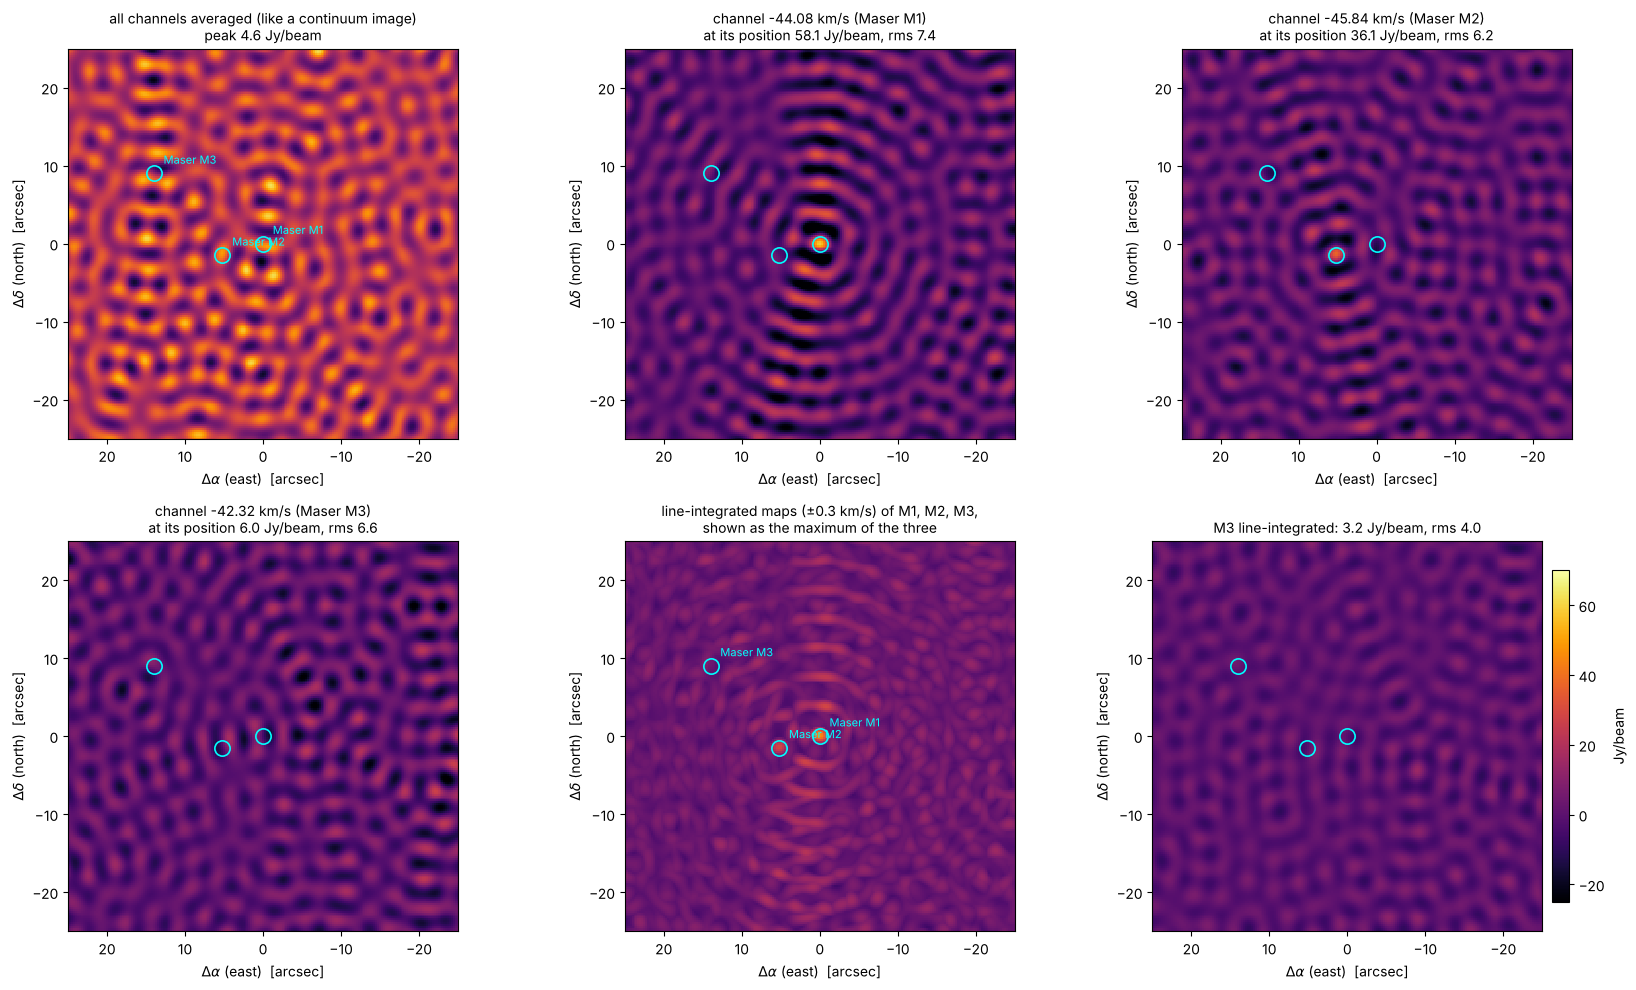

In [6]:
imgr = Imager(Gridder(512, 0.25), NaturalWeighting())
marks = sky_marks(masers, M1)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
cont = imgr.dirty_image(rg.average_channels(), center_deg=M1)
plot_image(cont, ax=axes[0, 0], zoom_arcsec=25, marks=marks, labels=True, colorbar=False,
           title=f"all channels averaged (like a continuum image)\npeak {cont.peak()[0]:.1f} Jy/beam")
panels = []
for ax, c in zip([axes[0, 1], axes[0, 2], axes[1, 0]], masers):
    k = int(np.argmin(np.abs(VAX - masers.spectra[c.name].v_kms)))
    im = imgr.channel_images(rg, [k], center_deg=M1)[0]
    l, m = (c.dx_deg - M1[0]) * 3600, (c.dy_deg - M1[1]) * 3600
    plot_image(im, ax=ax, zoom_arcsec=25, marks=marks, colorbar=False, vmin=-25, vmax=70,
               title=f"channel {VAX[k]:+.2f} km/s ({c.name})\nat its position {im.value_at(l, m):.1f} Jy/beam, rms {im.rms(4, (l, m)):.1f}")
    panels.append((c, k))
# line-integrated map: sum of the ±0.3 km/s channels around each maser velocity
mom = None
for c, k in panels:
    ks = [kk for kk in range(len(VAX)) if abs(VAX[kk] - VAX[k]) <= 0.3]
    ims = imgr.channel_images(rg, ks, center_deg=M1)
    avg = sum(i.data for i in ims) / len(ims)
    mom = avg if mom is None else np.maximum(mom, avg)
from interferosim.imaging import Image
mom_img = Image(mom, 0.25, "Jy/beam", M1, name="line-integrated")
plot_image(mom_img, ax=axes[1, 1], zoom_arcsec=25, marks=marks, labels=True, colorbar=False, vmin=-25, vmax=70,
           title="line-integrated maps (±0.3 km/s) of M1, M2, M3,\nshown as the maximum of the three")
c3 = masers["Maser M3"]; l3, m3 = (c3.dx_deg - M1[0]) * 3600, (c3.dy_deg - M1[1]) * 3600
k3 = panels[2][1]
im3 = imgr.channel_images(rg, [kk for kk in range(len(VAX)) if abs(VAX[kk] - VAX[k3]) <= 0.3], center_deg=M1)
avg3 = Image(sum(i.data for i in im3) / len(im3), 0.25, "Jy/beam", M1)
plot_image(avg3, ax=axes[1, 2], zoom_arcsec=25, marks=marks, vmin=-25, vmax=70,
           title=f"M3 line-integrated: {avg3.value_at(l3, m3):.1f} Jy/beam, rms {avg3.rms(4, (l3, m3)):.1f}")
fig.tight_layout(); plt.show()

## 6. What happens without the Doppler correction

The same data without regridding: averaging the topocentric channels over 16 h puts the line at the wrong velocity – shifted by the LSR correction of +10.8 km/s, i.e. at about −54.8 km/s if the axis is read as LSR – and broadens it by the drift within the night. Over a year the shift alone would move the line by 30 km/s, far out of a 22 km/s band.

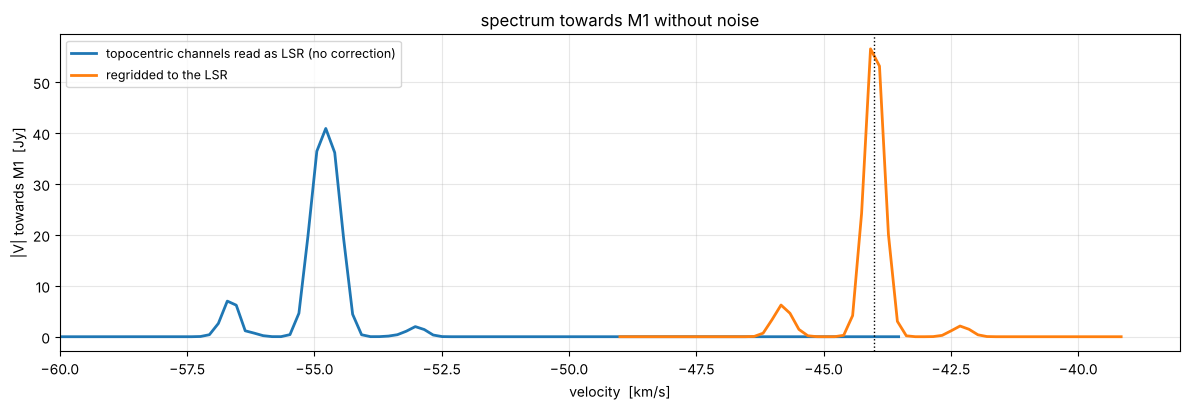

without correction the M1 line appears at -54.78 km/s; after regridding at -44.08 km/s


In [7]:
s_topo, _ = spectrum_towards(vd0, *M1)
v_naive = radio_velocity_kms(vd0.freq_hz, OH_1665)              # topocentric axis read as if it were LSR
s_lsr, _ = spectrum_towards(rg0, *M1)
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(v_naive, np.abs(s_topo), lw=2, label="topocentric channels read as LSR (no correction)")
ax.plot(VAX, np.abs(s_lsr), lw=2, label="regridded to the LSR")
ax.axvline(-44.0, color="k", ls=":", lw=1); ax.annotate("true -44.0 km/s", (-44.0, 60), xytext=(4, 0), textcoords="offset points")
ax.set(xlabel="velocity  [km/s]", ylabel="|V| towards M1  [Jy]", title="spectrum towards M1 without noise", xlim=(-60, -38))
ax.grid(alpha=0.3); ax.legend(fontsize=9); fig.tight_layout(); plt.show()
k = np.argmax(np.abs(s_topo))
print(f"without correction the M1 line appears at {v_naive[k]:+.2f} km/s; after regridding at {VAX[np.argmax(np.abs(s_lsr))]:+.2f} km/s")

## 7. HI absorption against Cygnus A

Band 1 MHz around −40 km/s, 128 channels (1.6 km/s), ±8 h, two-minute integrations. The continuum of Cygnus A is absorbed by Galactic HI clouds on the line of sight. Because the absorption multiplies the source, it also multiplies every visibility, whatever the baseline resolves: the **ratio** of line and continuum visibility gives the optical depth even on baselines that see only the hotspots,

$$e^{-\tau(v)} = \frac{V(v)}{V_\mathrm{cont}}, \qquad \hat R(v) = \frac{\sum_r V_r(v)\,V^*_{r,\mathrm{cont}}}{\sum_r |V_{r,\mathrm{cont}}|^2},$$

with the continuum $V_{r,\mathrm{cont}}$ of each row from the line-free channels. (Here all components carry the same absorption; in reality the hotspots 2′ apart probe different gas – exactly what VLBI absorption studies exploit.)

project baseline 11.5 km east-west (model): tau(+3 km/s) = 0.60, tau(-80 km/s) = 0.34, rms in line-free channels 0.049; mean |V_cont| 39 Jy, noise per visibility and channel 58 Jy


hypothetical three-station array: tau(+3 km/s) = 0.59, tau(-80 km/s) = 0.33, rms in line-free channels 0.020; mean |V_cont| 46 Jy, noise per visibility and channel 58 Jy


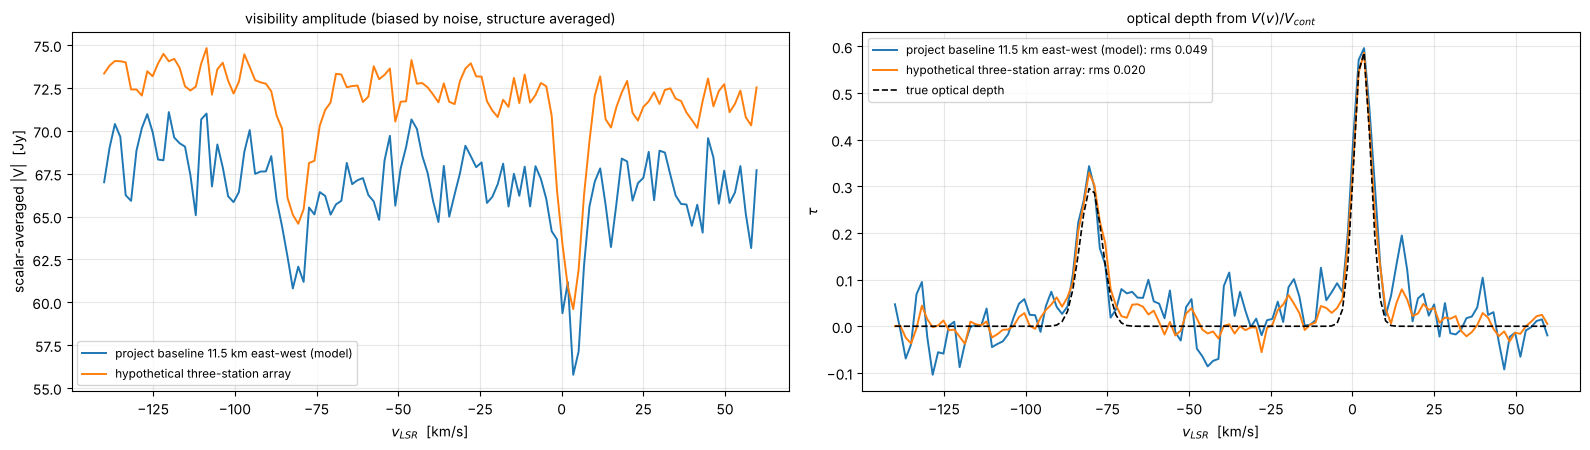

In [8]:
VH = np.arange(-140, 60, 1.65)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
true_tau = cyga.spectra["West hotspot A"].tau(frequency_from_velocity(VH, HI_21CM))
for arr, col in ((target, "C0"), (three, "C1")):
    o = Observation.from_sky(cyga, arr, ha_range_h=(-8, 8), t_int_s=120, date=DATE)
    vh = SpectralVisibilitySimulator(n_chan=128, bandwidth_hz=1e6, rest_hz=HI_21CM, v_center_kms=-40.0).run(cyga, o)
    rgh = regrid_to_lsr(vh, arr, HI_21CM, VH)
    ok = rgh.weight.min(axis=0) > 0
    free = ok & ((VH < -100) | ((VH > -60) & (VH < -20)) | (VH > 25))
    vcont = rgh.vis[:, free].mean(axis=1)
    R = (rgh.vis * np.conj(vcont)[:, None]).sum(0) / np.sum(np.abs(vcont) ** 2)
    tau = -np.log(np.clip(R.real, 1e-3, None))
    axes[0].plot(VH[ok], np.abs(rgh.vis[:, ok]).mean(0), color=col, lw=1.4, label=f"{arr.name}")
    axes[1].plot(VH[ok], tau[ok], color=col, lw=1.4, label=f"{arr.name}: rms {np.std(tau[free]):.3f}")
    print(f"{arr.name}: tau(+3 km/s) = {tau[np.argmin(np.abs(VH - 3))]:.2f}, tau(-80 km/s) = {tau[np.argmin(np.abs(VH + 80))]:.2f}, "
          f"rms in line-free channels {np.std(tau[free]):.3f}; mean |V_cont| {np.abs(vcont).mean():.0f} Jy, "
          f"noise per visibility and channel {vh.sigma[0, 0]:.0f} Jy")
axes[1].plot(VH, true_tau, "k--", lw=1.2, label="true optical depth")
axes[0].set(xlabel=r"$v_{LSR}$  [km/s]", ylabel="scalar-averaged |V|  [Jy]",
            title="visibility amplitude (biased by noise, structure averaged)")
axes[1].set(xlabel=r"$v_{LSR}$  [km/s]", ylabel=r"$\tau$", title=r"optical depth from $V(v)/V_{cont}$")
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=8.5); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()

## 8. Planning a real line observation with the B210

The B210 records 2 MHz around the LO (notebook 08); the line work is done by the FX correlator with enough channels. For the masers the relevant question is the integration time for a given signal-to-noise ratio per channel on the 11.5 km baseline:

$$t = \frac{(\mathrm{S/N})^2\,\mathrm{SEFD}_1\,\mathrm{SEFD}_2}{2\,\Delta f\,S^2}.$$

In [9]:
print(f"{'target':<34s} {'channel':>9s} {'S [Jy]':>7s} {'SEFD [kJy]':>10s} {'t for S/N 5 per channel':>24s}")
for name, f0, S, D in [("M1 (70 Jy), two 3 m dishes", OH_1665, 67, 3.0), ("M3 (20 Jy), two 3 m dishes", OH_1665, 19, 3.0),
                       ("M1, two 7.5 m dishes (hypothetical)", OH_1665, 67, 7.5)]:
    se = b210.sefd_jy(dish, f0) * (3.0 / D) ** 2            # same efficiency and T_sys, area ~ D^2
    df = 125e3 / 128
    t = 25 * se * se / (2 * df * S ** 2)
    print(f"{name:<34s} {df:7.0f} Hz {S:7.0f} {se / 1e3:10.0f} {t / 3600:21.1f} h")
fft = int(2e6 / (125e3 / 128))
print(f"\nB210 at 2 MS/s: channels of {125e3 / 128:.0f} Hz need an FFT length of {fft} (or decimation of the recording to 125 kHz);"
      f" the LO is set once from topocentric_frequency_hz for the middle of the session, regrid_to_lsr does the rest.")

target                               channel  S [Jy] SEFD [kJy]  t for S/N 5 per channel
M1 (70 Jy), two 3 m dishes             977 Hz      67         78                   4.8 h
M3 (20 Jy), two 3 m dishes             977 Hz      19         78                  60.1 h
M1, two 7.5 m dishes (hypothetical)     977 Hz      67         13                   0.1 h

B210 at 2 MS/s: channels of 977 Hz need an FFT length of 2048 (or decimation of the recording to 125 kHz); the LO is set once from topocentric_frequency_hz for the middle of the session, regrid_to_lsr does the rest.


Spectral-line work on the 11.5 km baseline with 3 m dishes is possible but slow: the brightest maser needs about 5 h for S/N 5 per channel, a 20 Jy maser about 60 h. The time falls with the fourth power of the dish diameter (SEFD ∝ 1/D², t ∝ SEFD²): two 7.5 m dishes would need minutes.

## 9. Selector

Source, array, band, number of channels, centre velocity, Doppler correction, velocity and position for the spectrum; *Run Interact* shows the spectrum towards the chosen position (vector average, after regridding) and the channel map at the chosen velocity. (Needs a running kernel.)

In [10]:
import ipywidgets as widgets
from IPython.display import display

SK9 = {"w3oh_masers_lines (OH 1665)": (masers, OH_1665, M1, Gridder(512, 0.25), 25, 60),
       "cyg_a_hi (HI)": (cyga, HI_21CM, (0.0, 0.0), Gridder(512, 0.5), 80, 120)}
AR9 = {"project baseline 11.5 km": target, "three stations (hypothetical)": three}

def run_lines(source, array_name, bandwidth_khz, n_chan, v_center, doppler, v_map, position):
    sky, f0, cen, grid, zoom, tint = SK9[source]
    arr = AR9[array_name]
    o = Observation.from_sky(sky, arr, ha_range_h=(-8, 8), t_int_s=tint, freq_hz=f0, date=DATE)
    d = SpectralVisibilitySimulator(n_chan=n_chan, bandwidth_hz=bandwidth_khz * 1e3, rest_hz=f0,
                                    v_center_kms=v_center, doppler=doppler).run(sky, o)
    dv = C_KMS * d.header["CHANWID"] / f0
    span = C_KMS * bandwidth_khz * 1e3 / f0
    vax = np.arange(v_center - 0.45 * span, v_center + 0.45 * span, dv)
    r = regrid_to_lsr(d, arr, f0, vax) if doppler else d
    vplot = vax if doppler else radio_velocity_kms(d.freq_hz, f0)
    comp = {c.name: c for c in sky}
    pos = comp[position] if position in comp else None
    l, m = (pos.dx_deg, pos.dy_deg) if pos else cen
    s, e = spectrum_towards(r, l, m)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
    axes[0].plot(vplot, s.real, lw=1.4); axes[0].fill_between(vplot, -2 * e, 2 * e, color="0.85")
    axes[0].axvline(v_map, color="C3", ls="--")
    axes[0].set(xlabel="velocity  [km/s]" + (" (LSR)" if doppler else " (topocentric)"), ylabel="Re V  [Jy]",
                title=f"spectrum towards {position}"); axes[0].grid(alpha=0.3)
    k = int(np.argmin(np.abs(vplot - v_map)))
    im = Imager(grid, NaturalWeighting()).channel_images(r, [k], center_deg=cen)[0]
    plot_image(im, ax=axes[1], zoom_arcsec=zoom, marks=sky_marks(sky, cen, min_flux_jy=10),
               title=f"channel {vplot[k]:+.2f} km/s, peak {im.peak()[0]:.1f} Jy/beam")
    fig.tight_layout(); plt.show()
    print(f"channel {dv:.3f} km/s, noise per visibility and channel {d.sigma[0, 0]:.0f} Jy, "
          f"mean LSR correction {d.header['VLSRCORR']:+.2f} km/s")

display(widgets.interactive(
    run_lines, {"manual": True},
    source=widgets.Dropdown(options=list(SK9), description="source"),
    array_name=widgets.Dropdown(options=list(AR9), description="array"),
    bandwidth_khz=widgets.Dropdown(options=[62.5, 125.0, 250.0, 1000.0, 2000.0], value=125.0, description="band [kHz]"),
    n_chan=widgets.Dropdown(options=[32, 64, 128, 256], value=128, description="channels"),
    v_center=widgets.FloatText(value=-44.0, description="v centre"),
    doppler=widgets.Checkbox(value=True, description="Doppler to LSR"),
    v_map=widgets.FloatText(value=-44.0, description="v map"),
    position=widgets.Dropdown(options=["field centre", "Maser M1", "Maser M2", "Maser M3", "West hotspot A", "East hotspot D"],
                              value="Maser M1", description="spectrum at"),
))

interactive(children=(Dropdown(description='source', options=('w3oh_masers_lines (OH 1665)', 'cyg_a_hi (HI)'),…